In [405]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import mutual_info_score
from sklearn.feature_selection import mutual_info_regression
import xgboost as xgb
from sklearn.feature_extraction import DictVectorizer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import roc_auc_score

Import Data

In [269]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("chaitanyajamble/grade-prediction-based-on-socioeconomic-factors")

print("Path to dataset files:", path)

Path to dataset files: /Users/freddiewhichello/.cache/kagglehub/datasets/chaitanyajamble/grade-prediction-based-on-socioeconomic-factors/versions/1


In [270]:
df = pd.read_csv(r'student_grade_ses_dataset.csv')

Data Cleaning

In [271]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12025 entries, 0 to 12024
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  12025 non-null  str    
 1   academic_year               12025 non-null  str    
 2   survey_date                 12025 non-null  str    
 3   age                         12025 non-null  int64  
 4   gender                      12025 non-null  str    
 5   grade_level                 12025 non-null  int64  
 6   school_type                 12025 non-null  str    
 7   residence_type              12025 non-null  str    
 8   family_size                 12025 non-null  int64  
 9   num_siblings                12025 non-null  int64  
 10  single_parent_household     12025 non-null  int64  
 11  family_income_bracket       12025 non-null  str    
 12  annual_family_income_inr    11304 non-null  float64
 13  father_education_level      11605 non-null

Checking duplicates

In [272]:
df.duplicated(subset=['student_id']).sum()

np.int64(25)

In [273]:
df[df.duplicated(subset=['student_id'], keep=False)].sort_values('student_id')

,student_id,academic_year,survey_date,age,gender,grade_level,school_type,residence_type,family_size,num_siblings,...,distance_to_school_km,scholarship_status,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,grade_class,at_risk_flag
6089,STU100191,2022-2023,2025-03-08,15,Female,10,Government,Semi-Urban,3,1,...,2.1,No Scholarship,0,2,15.1,79.4,67.7,74.8,C,0
4725,STU100191,2022-2023,2025-03-08,15,Female,10,Government,Semi-Urban,3,1,...,2.1,No Scholarship,0,2,15.1,79.4,67.7,74.8,C,0
45,STU100247,2024-2025,2025-03-10,13,Male,8,Private-Unaided,Urban,5,3,...,1.1,No Scholarship,0,3,13.2,83.8,40.4,47.0,D,0
2052,STU100247,2024-2025,2025-03-10,13,Male,8,Private-Unaided,Urban,5,3,...,1.1,No Scholarship,0,3,13.2,83.8,40.4,47.0,D,0
8776,STU100694,2022-2023,2025-03-16,11,Male,6,Government-Aided,Urban,4,2,...,1.2,Full,0,3,16.6,82.7,49.6,60.8,C,0
4693,STU100694,2022-2023,2025-03-16,11,Male,6,Government-Aided,Urban,4,2,...,1.2,Full,0,3,16.6,82.7,49.6,60.8,C,0
2693,STU100921,2022-2023,2025-04-22,14,Male,10,Government,Rural,5,3,...,0.8,Partial,0,3,13.9,73.3,57.9,50.6,D,0
11612,STU100921,2022-2023,2025-04-22,14,Male,10,Government,Rural,5,3,...,0.8,Partial,0,3,13.9,73.3,57.9,50.6,D,0
7700,STU101857,2021-2022,2025-05-10,14,Female,10,Government,Urban,6,4,...,3.5,No Scholarship,0,3,16.2,93.4,53.7,59.1,D,0
3746,STU101857,2021-2022,2025-05-10,14,Female,10,Government,Urban,6,4,...,3.5,No Scholarship,0,3,16.2,93.4,53.7,59.1,D,0


In [274]:
df[df['student_id']=='STU100191']

,student_id,academic_year,survey_date,age,gender,grade_level,school_type,residence_type,family_size,num_siblings,...,distance_to_school_km,scholarship_status,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,grade_class,at_risk_flag
4725,STU100191,2022-2023,2025-03-08,15,Female,10,Government,Semi-Urban,3,1,...,2.1,No Scholarship,0,2,15.1,79.4,67.7,74.8,C,0
6089,STU100191,2022-2023,2025-03-08,15,Female,10,Government,Semi-Urban,3,1,...,2.1,No Scholarship,0,2,15.1,79.4,67.7,74.8,C,0


In [275]:
df = df.drop_duplicates()

In [276]:
df[df['student_id']=='STU100191']


,student_id,academic_year,survey_date,age,gender,grade_level,school_type,residence_type,family_size,num_siblings,...,distance_to_school_km,scholarship_status,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,grade_class,at_risk_flag
4725,STU100191,2022-2023,2025-03-08,15,Female,10,Government,Semi-Urban,3,1,...,2.1,No Scholarship,0,2,15.1,79.4,67.7,74.8,C,0


In [277]:
df[df.duplicated(subset=['student_id'], keep=False)].sort_values('student_id')

,student_id,academic_year,survey_date,age,gender,grade_level,school_type,residence_type,family_size,num_siblings,...,distance_to_school_km,scholarship_status,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,grade_class,at_risk_flag


Fill na values

In [278]:
#fill categorical columns missing values with na
for c in df.columns:
    if df[c].dtype == 'str':
        df[c] = df[c].fillna('na')

In [279]:
#analysis for filling in int na values
df['residence_type'].unique()

<StringArray>
['Rural', 'Urban', 'Semi-Urban']
Length: 3, dtype: str

In [280]:
df.groupby(['family_income_bracket', 'residence_type','has_computer_or_laptop'])['has_internet_access'].agg(['median', 'mean'])

median      mean
family_income_bracket residence_type has_computer_or_laptop                  
High                  Rural          0                          1.0  0.563910
                                     1                          1.0  0.619565
                      Semi-Urban     0                          1.0  0.694915
                                     1                          1.0  0.766667
                      Urban          0                          1.0  0.827586
                                     1                          1.0  0.826241
Low                   Rural          0                          0.0  0.213811
                                     1                          0.0  0.165289
                      Semi-Urban     0                          0.0  0.383795
                                     1                          0.0  0.341040
                      Urban          0                          0.0  0.453488
                                     1                          0.0  0.477573
Lower-Middle          Rural          0                          0.0  0.315376
                                     1                          0.0  0.288820
                      Semi-Urban     0                          0.0  0.474771
                                     1                          0.0  0.471831
                      Urban          0                          1.0  0.551678
                                     1                          1.0  0.613419
Middle                Rural          0                          0.0  0.387964
                                     1                          0.0  0.424242
                      Semi-Urban     0                          1.0  0.572072
                                     1                          1.0  0.575668
                      Urban          0                          1.0  0.626340
                                     1                          1.0  0.628651
Upper-Middle          Rural          0                          0.0  0.491018
                                     1                          0.0  0.461255
                      Semi-Urban     0                          1.0  0.549383
                                     1                          1.0  0.606195
                      Urban          0                          1.0  0.679537
                                     1                          1.0  0.697495

In [281]:
df.groupby(['residence_type'])['distance_to_school_km'].agg(['median', 'mean'])

,median,mean
residence_type,,
Rural,5.4,6.370969
Semi-Urban,3.0,3.542226
Urban,1.7,1.982472


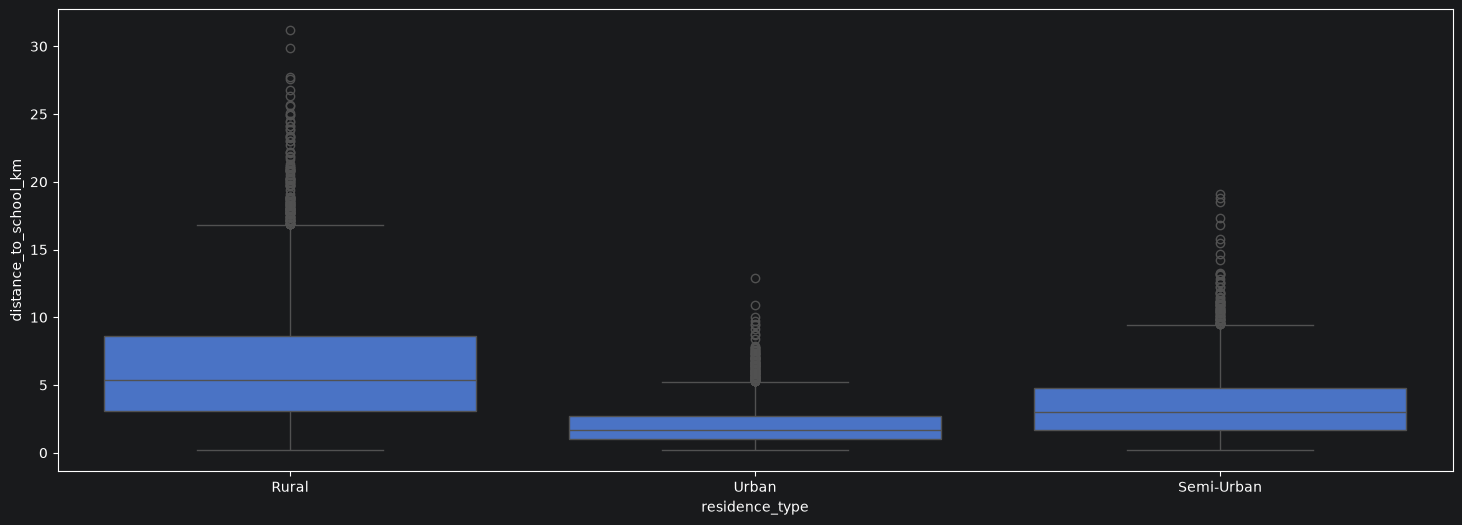

In [282]:
fig, ax= plt.subplots(figsize=(18, 6))
sns.boxplot(x="residence_type", y="distance_to_school_km", data=df)

plt.show()

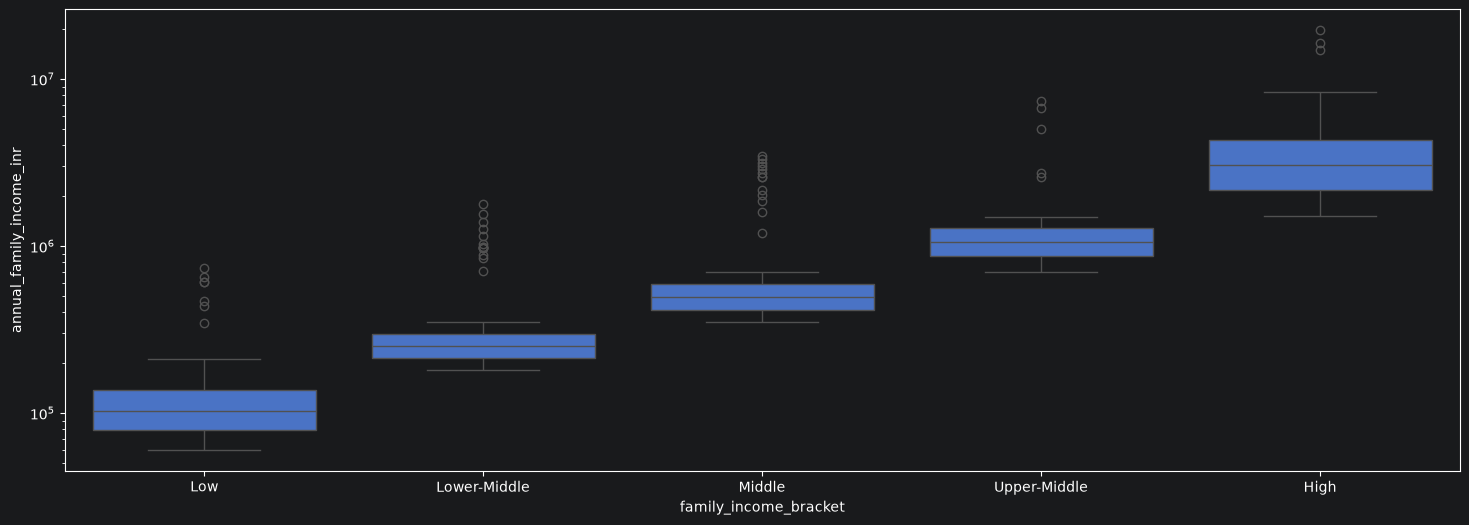

In [283]:
fig, ax= plt.subplots(figsize=(18, 6))
ax.set_yscale('log')
custom_order = ["Low", "Lower-Middle", "Middle",  "Upper-Middle", "High"]
sns.boxplot(x="family_income_bracket", y="annual_family_income_inr", data=df, ax=ax, order=custom_order)

plt.show()

In [284]:
df.groupby('family_income_bracket')['annual_family_income_inr'].agg(['median', 'mean'])

,median,mean
family_income_bracket,,
High,3069257.0,3.348148e+06
Low,103092.0,1.102218e+05
Lower-Middle,252893.0,2.599130e+05
Middle,495154.5,5.127675e+05
Upper-Middle,1052217.0,1.083757e+06


In [285]:
df.groupby(['family_income_bracket', 'residence_type'])['attendance_rate_pct'].agg(['mean', 'median'])

mean  median
family_income_bracket residence_type                   
High                  Rural           87.880707   88.20
                      Semi-Urban      90.734831   91.45
                      Urban           91.417367   92.80
Low                   Rural           80.906774   80.80
                      Semi-Urban      84.385871   84.40
                      Urban           84.259677   84.20
Lower-Middle          Rural           82.528241   82.20
                      Semi-Urban      86.505882   86.85
                      Urban           86.394952   86.60
Middle                Rural           84.010317   84.00
                      Semi-Urban      88.039583   88.10
                      Urban           88.066419   88.20
Upper-Middle          Rural           85.711647   85.70
                      Semi-Urban      89.175457   89.70
                      Urban           89.005208   89.50

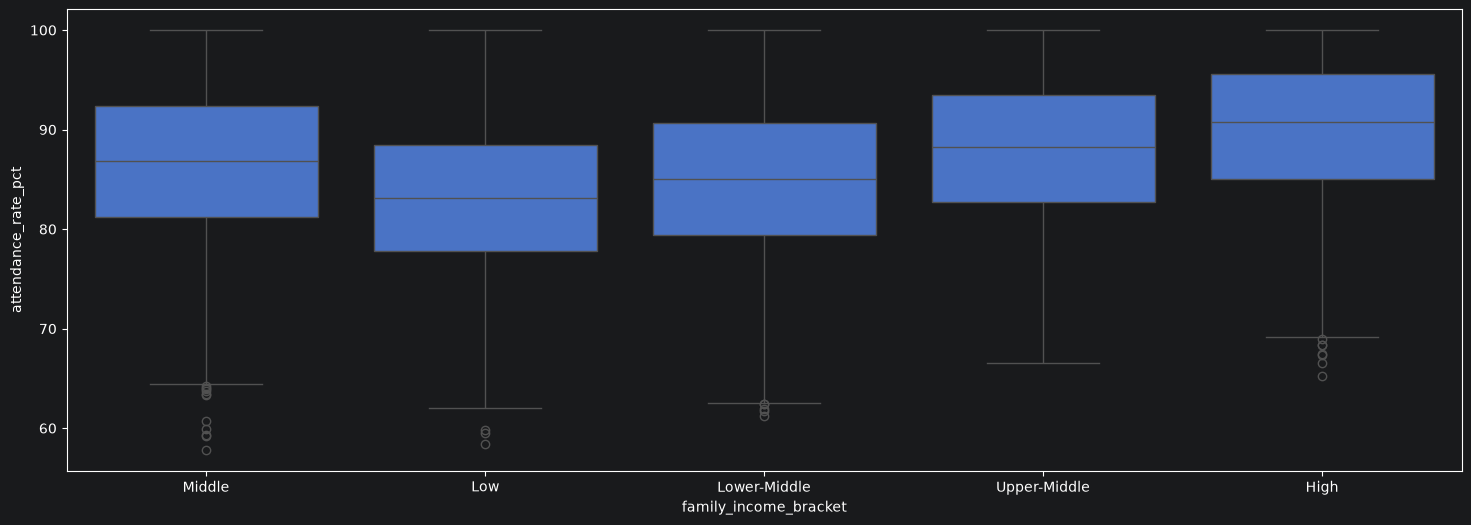

In [286]:
fig, ax= plt.subplots(figsize=(18, 6))
sns.boxplot(x='family_income_bracket', y="attendance_rate_pct", data=df)
plt.show()

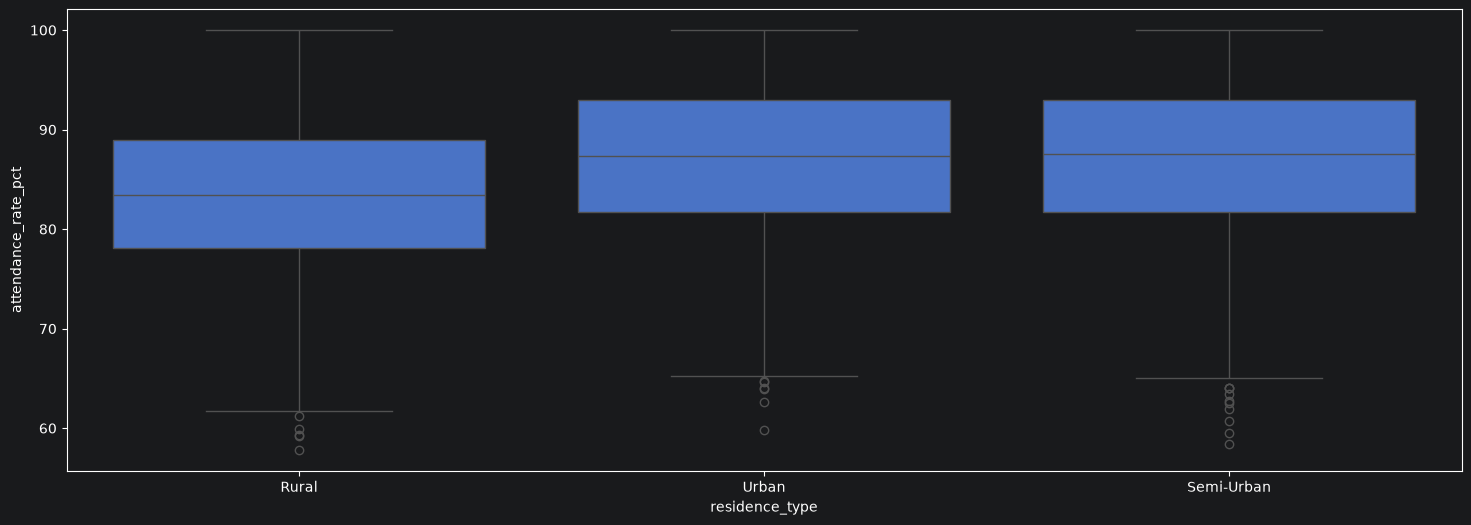

In [287]:
fig, ax= plt.subplots(figsize=(18, 6))
sns.boxplot(x='residence_type', y="attendance_rate_pct", data=df)
plt.show()

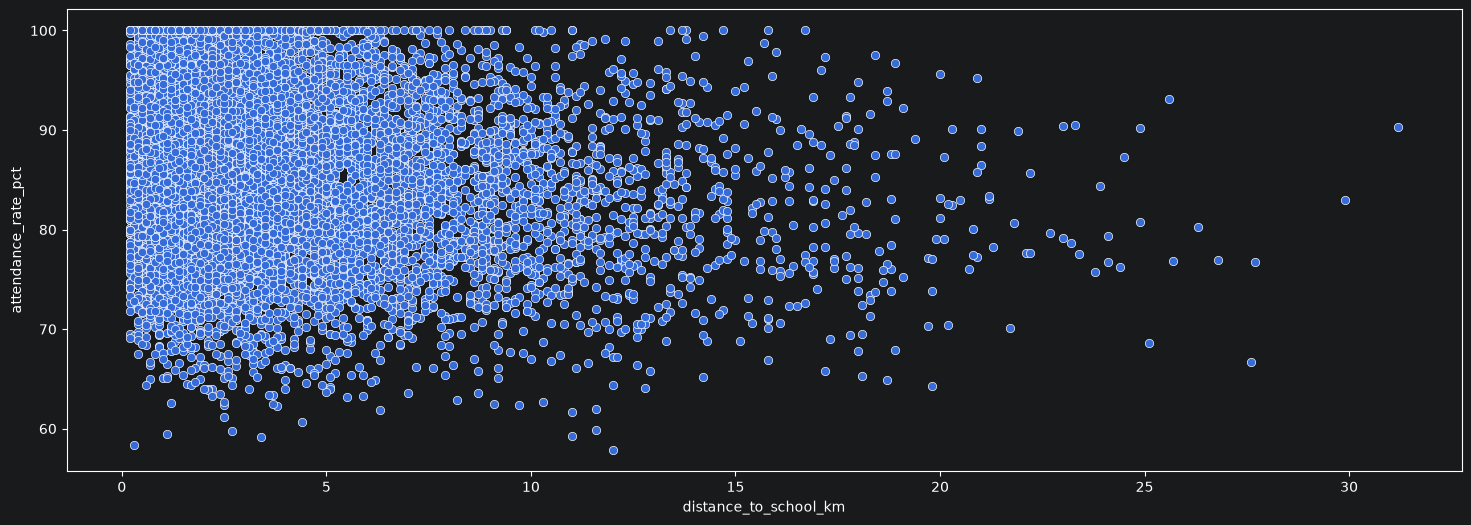

In [288]:
fig, ax= plt.subplots(figsize=(18, 6))
sns.scatterplot(x='distance_to_school_km', y="attendance_rate_pct", data=df)
plt.show()

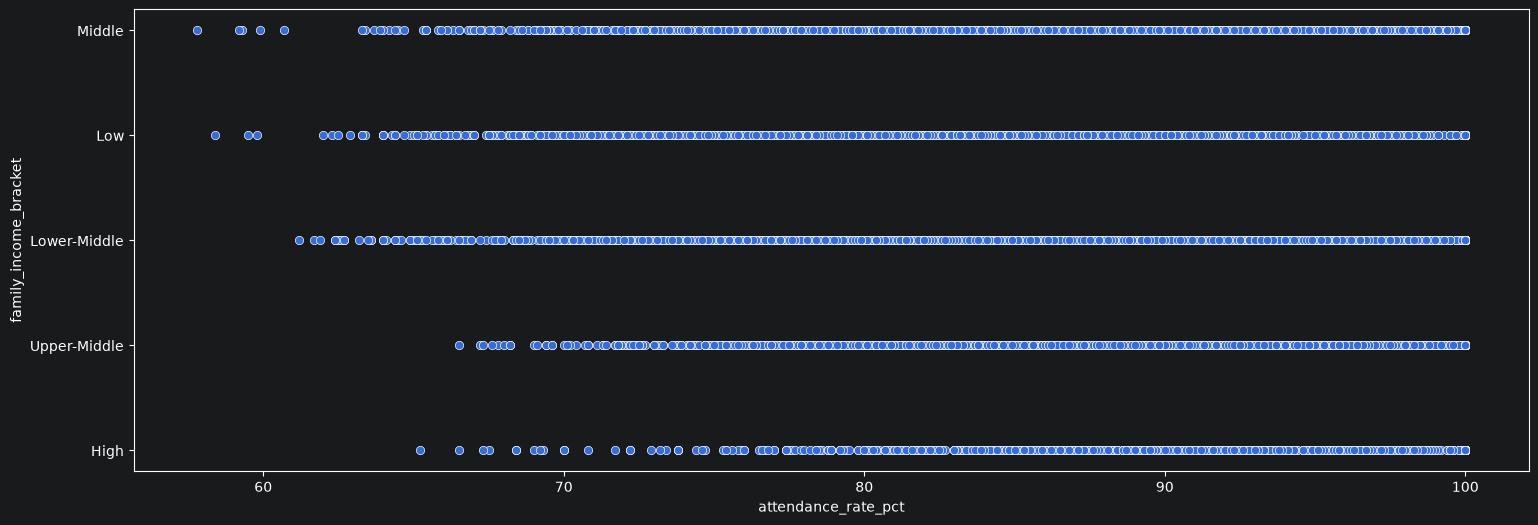

In [289]:
fig, ax= plt.subplots(figsize=(18, 6))
sns.scatterplot(x='attendance_rate_pct', y="family_income_bracket", data=df)
plt.show()

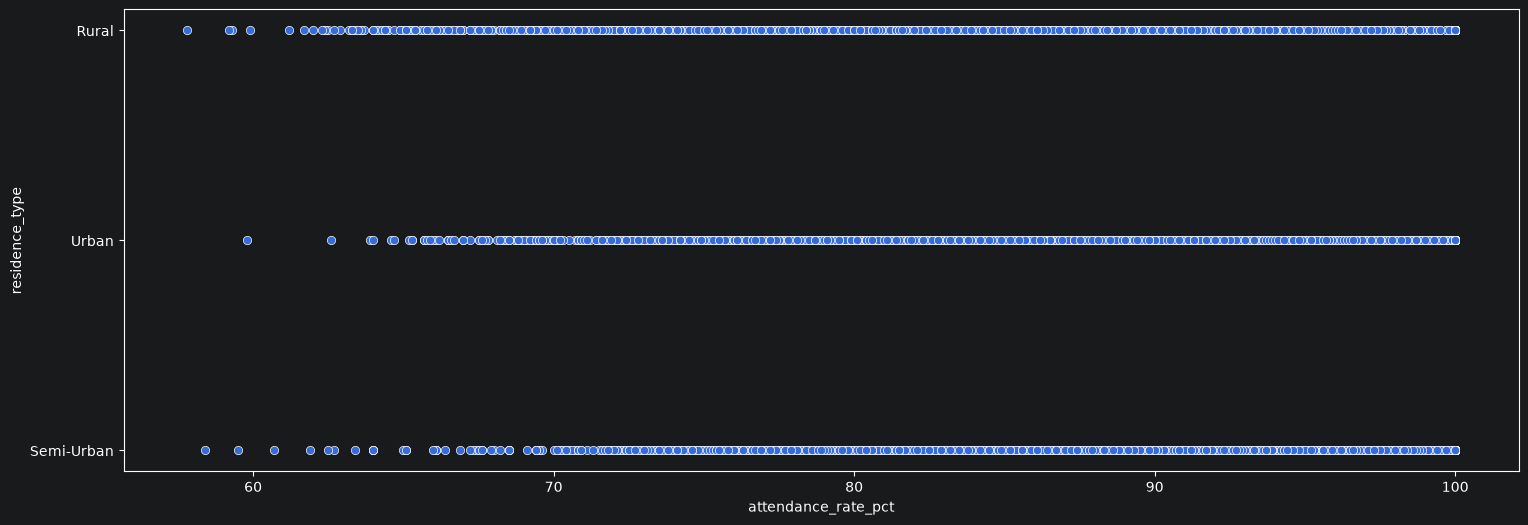

In [290]:
fig, ax= plt.subplots(figsize=(18, 6))
sns.scatterplot(x='attendance_rate_pct', y='residence_type', data=df)
plt.show()

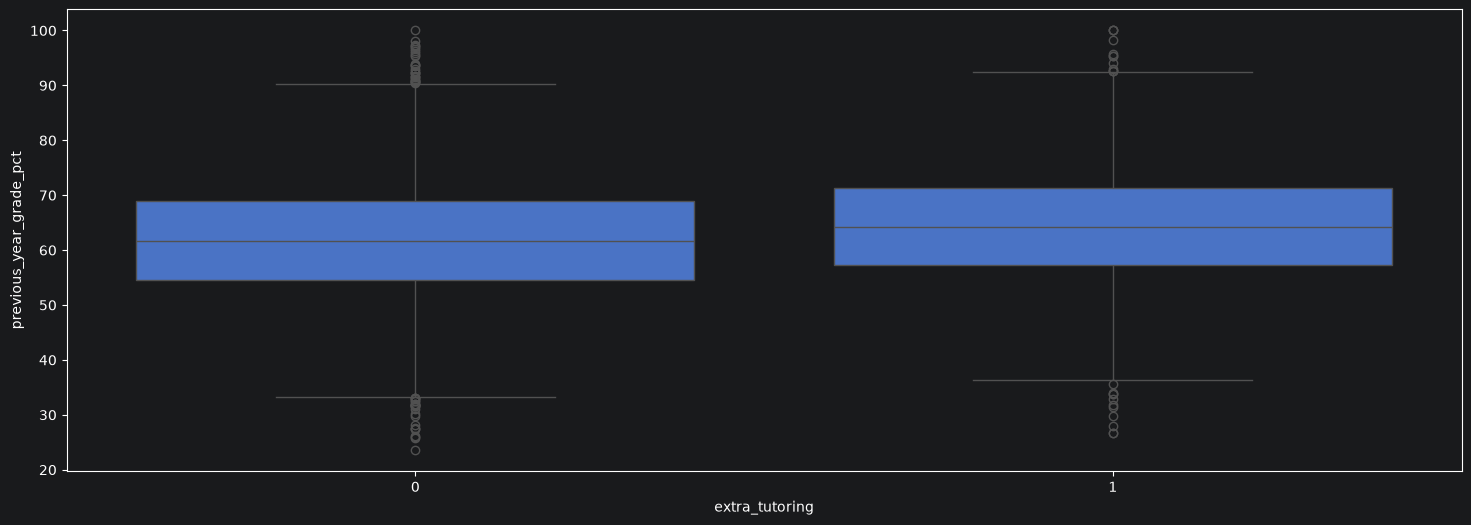

In [291]:
fig, ax= plt.subplots(figsize=(18, 6))
sns.boxplot(x='extra_tutoring', y="previous_year_grade_pct", data=df)
plt.show()

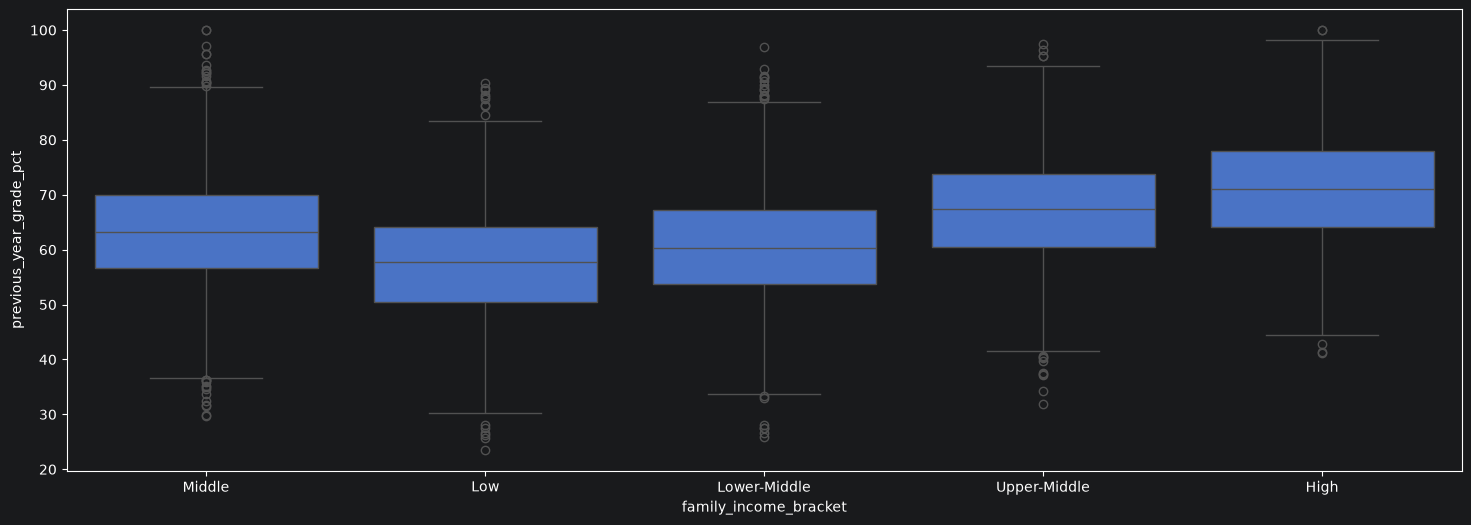

In [292]:
fig, ax= plt.subplots(figsize=(18, 6))
sns.boxplot(x='family_income_bracket', y="previous_year_grade_pct", data=df)
plt.show()

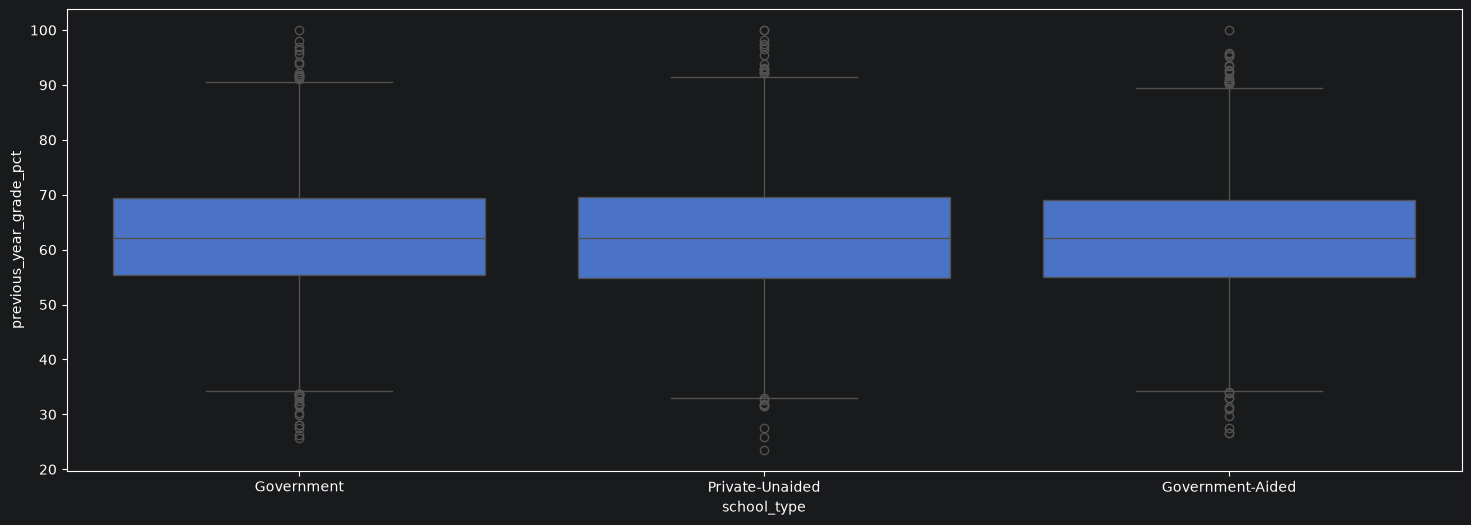

In [293]:
fig, ax= plt.subplots(figsize=(18, 6))
sns.boxplot(x='school_type', y="previous_year_grade_pct", data=df)
plt.show()

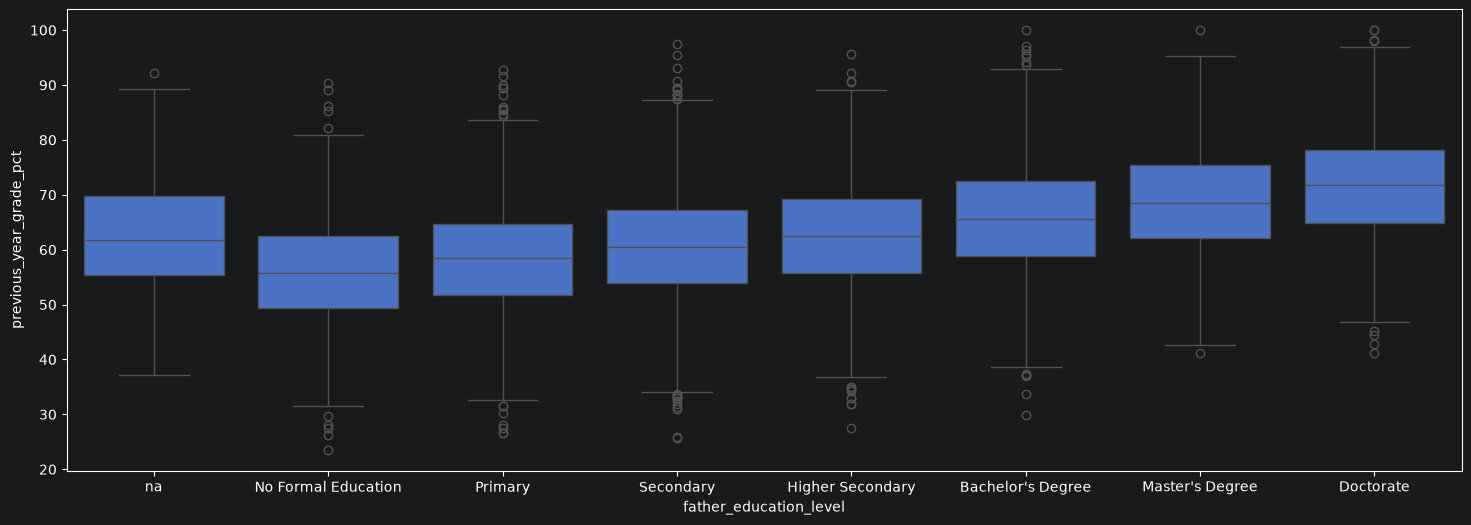

In [294]:
fig, ax= plt.subplots(figsize=(18, 6))
custom_order = ["na", "No Formal Education", "Primary",  "Secondary", "Higher Secondary", "Bachelor's Degree", "Master's Degree", "Doctorate"]
sns.boxplot(x='father_education_level', y="previous_year_grade_pct", data=df, order=custom_order)
plt.show()

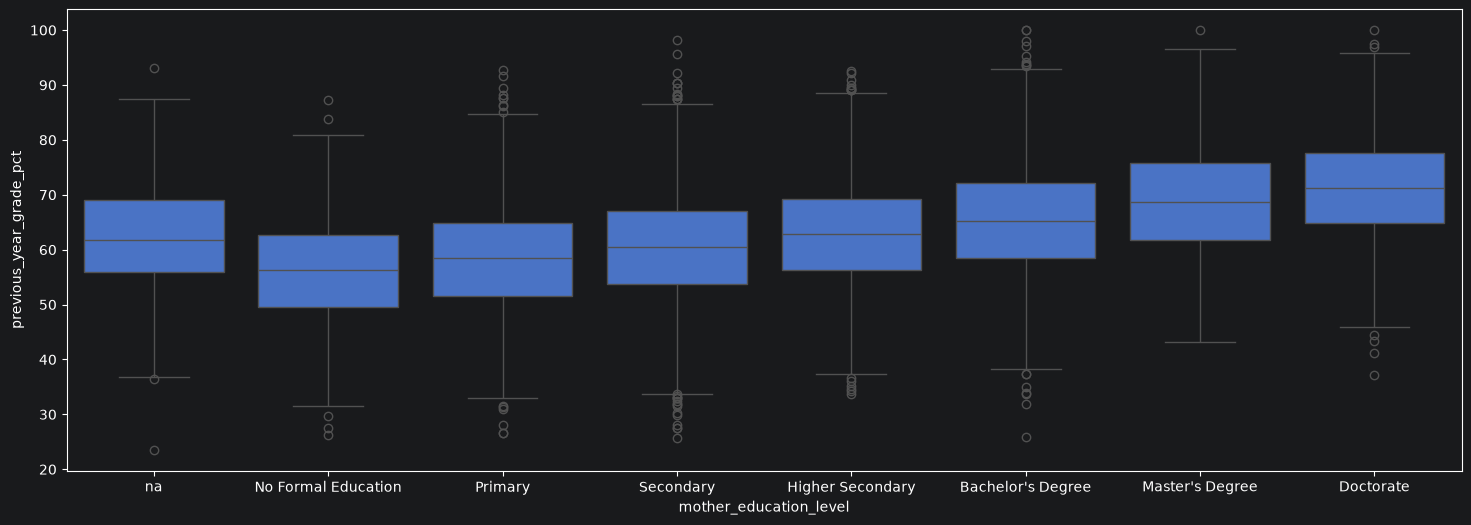

In [295]:
fig, ax= plt.subplots(figsize=(18, 6))
custom_order = ["na", "No Formal Education", "Primary",  "Secondary", "Higher Secondary", "Bachelor's Degree", "Master's Degree", "Doctorate"]
sns.boxplot(x='mother_education_level', y="previous_year_grade_pct", data=df, order=custom_order)
plt.show()

In [296]:
df.groupby(['family_income_bracket', 'residence_type'])['attendance_rate_pct'].agg(['mean', 'median'])

mean  median
family_income_bracket residence_type                   
High                  Rural           87.880707   88.20
                      Semi-Urban      90.734831   91.45
                      Urban           91.417367   92.80
Low                   Rural           80.906774   80.80
                      Semi-Urban      84.385871   84.40
                      Urban           84.259677   84.20
Lower-Middle          Rural           82.528241   82.20
                      Semi-Urban      86.505882   86.85
                      Urban           86.394952   86.60
Middle                Rural           84.010317   84.00
                      Semi-Urban      88.039583   88.10
                      Urban           88.066419   88.20
Upper-Middle          Rural           85.711647   85.70
                      Semi-Urban      89.175457   89.70
                      Urban           89.005208   89.50

In [303]:
df['annual_family_income_inr'] = df['annual_family_income_inr'].fillna(
    df.groupby('family_income_bracket')['annual_family_income_inr'].transform('median')
)

In [304]:
df['distance_to_school_km'] = df['distance_to_school_km'].fillna(
    df.groupby('residence_type')['distance_to_school_km'].transform('median')
)

In [305]:
df['has_internet_access'] = df['has_internet_access'].fillna(
    df.groupby(['family_income_bracket', 'residence_type','has_computer_or_laptop'])['has_internet_access'].transform('mean')
)

In [306]:
df['attendance_rate_pct'] = df['attendance_rate_pct'].fillna(
    df.groupby(['family_income_bracket', 'residence_type','scholarship_status'])['attendance_rate_pct'].transform('mean')
)

In [307]:
df['previous_year_grade_pct'] = df['previous_year_grade_pct'].fillna(
    df.groupby(['mother_education_level', 'father_education_level','scholarship_status'])['previous_year_grade_pct'].transform('mean')
)

In [308]:
df.info()

<class 'pandas.DataFrame'>
Index: 12000 entries, 0 to 12024
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  12000 non-null  str    
 1   academic_year               12000 non-null  str    
 2   survey_date                 12000 non-null  str    
 3   age                         12000 non-null  int64  
 4   gender                      12000 non-null  str    
 5   grade_level                 12000 non-null  int64  
 6   school_type                 12000 non-null  str    
 7   residence_type              12000 non-null  str    
 8   family_size                 12000 non-null  int64  
 9   num_siblings                12000 non-null  int64  
 10  single_parent_household     12000 non-null  int64  
 11  family_income_bracket       12000 non-null  str    
 12  annual_family_income_inr    12000 non-null  float64
 13  father_education_level      12000 non-null  str

EDA

<Axes: xlabel='final_grade_pct', ylabel='Count'>

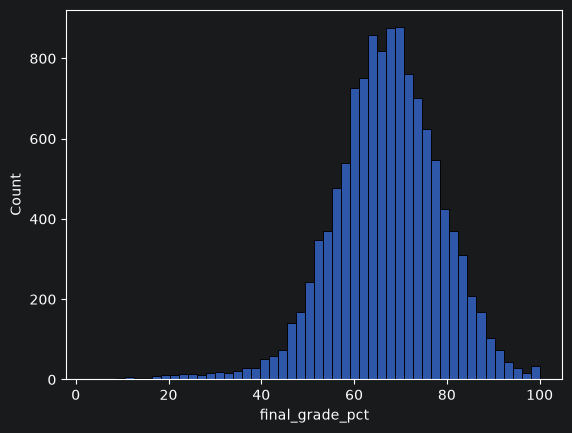

In [309]:
sns.histplot(data=df, x='final_grade_pct', bins=50)

<Axes: xlabel='final_grade_pct', ylabel='previous_year_grade_pct'>

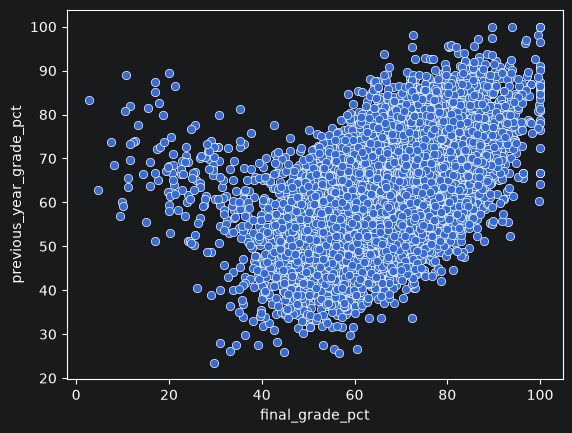

In [310]:
sns.scatterplot(data=df, x='final_grade_pct', y='previous_year_grade_pct')

In [311]:
df['final_grade_pct'].describe()

count    12000.000000
mean        66.944467
std         11.697114
min          2.800000
25%         60.100000
50%         67.300000
75%         74.600000
max        100.000000
Name: final_grade_pct, dtype: float64

Checking missing values

In [312]:
df.isna().sum()

student_id                    0
academic_year                 0
survey_date                   0
age                           0
gender                        0
grade_level                   0
school_type                   0
residence_type                0
family_size                   0
num_siblings                  0
single_parent_household       0
family_income_bracket         0
annual_family_income_inr      0
father_education_level        0
mother_education_level        0
father_occupation             0
mother_occupation             0
has_internet_access           0
has_computer_or_laptop        0
distance_to_school_km         0
scholarship_status            0
extra_tutoring                0
parental_involvement_score    0
study_hours_per_week          0
attendance_rate_pct           0
previous_year_grade_pct       0
final_grade_pct               0
grade_class                   0
at_risk_flag                  0
dtype: int64

Feature Importance

In [313]:
global_grade = df['final_grade_pct'].mean()
global_grade

np.float64(66.94446666666667)

In [314]:
total_grade_variation = ((df['final_grade_pct'] - global_grade) ** 2).sum()
total_grade_variation

np.float64(1641732.8525866666)

In [315]:
categorical_columns = ['student_id',
                       'academic_year',
                       'survey_date',
                       'gender',
                       'school_type',
                       'residence_type',
                       'family_income_bracket',
                       'father_education_level',
                       'mother_education_level',
                       'father_occupation',
                       'mother_occupation',
                       'scholarship_status',
                       'grade_class']

In [316]:

category_tables = []
importance_rows = []

for column in categorical_columns:
  group_grade = (
    df.groupby(column, dropna=False)['final_grade_pct']
      .agg(group_count='size', group_grade='mean')
      .reset_index()
      .rename(columns={column: 'category'})
  )

  group_grade['feature'] = column

  # Calculate the risk and diff of each group of the feature
  group_grade['difference'] = global_grade - group_grade['group_grade']
  group_grade['risk'] = group_grade['group_grade'] / global_grade
  category_tables.append(group_grade)

  # Calculate feature importance
  between_group_variation = (
    group_grade['group_grade']
    * (group_grade['group_grade'] - global_grade) ** 2
  ).sum()

  importance_rows.append({
    'feature': column,
    'groups': len(group_grade),
    # How much grades differ across a feature's groups
    # closer to 0 means the groups' average grades are fairly similar, closer to 1 means they differ more
    'eta_squared': between_group_variation / total_grade_variation,
    # The number of examples in the least represented category
    # A small number means that category's average price may be based on very little information
    'smallest_group_n': group_grade['group_count'].min(),
  })

In [317]:
category_grade_summary = (
  pd.concat(category_tables, ignore_index=True)
    [['feature', 'category', 'group_count', 'group_grade', 'difference', 'risk']]
    .sort_values(['feature', 'group_grade'], ascending=[True, False])
)

category_grade_summary

,feature,category,group_count,group_grade,difference,risk
12001,academic_year,2022-2023,2704,67.136612,-0.192146,1.002870
12000,academic_year,2021-2022,2124,66.983098,-0.038631,1.000577
12002,academic_year,2023-2024,3338,66.877621,0.066845,0.999001
12003,academic_year,2024-2025,3834,66.845749,0.098718,0.998525
12088,family_income_bracket,High,873,76.422680,-9.478214,1.141583
...,...,...,...,...,...,...
12066,survey_date,2025-05-02,164,65.403659,1.540808,0.976984
12078,survey_date,2025-05-14,144,65.306944,1.637522,0.975539
12067,survey_date,2025-05-03,150,65.223333,1.721133,0.974290
12076,survey_date,2025-05-12,149,64.964430,1.980037,0.970423


In [318]:
feature_importance = (
  pd.DataFrame(importance_rows)
    .sort_values('eta_squared', ascending=False)
    .reset_index(drop=True)
)

feature_importance

,feature,groups,eta_squared,smallest_group_n
0,student_id,12000,6.070791e+01,1
1,grade_class,5,8.121964e-02,209
2,father_education_level,8,8.071353e-03,361
3,mother_education_level,8,7.688135e-03,360
4,family_income_bracket,5,6.201835e-03,873
5,survey_date,75,3.052474e-03,128
6,mother_occupation,9,7.781846e-04,600
7,father_occupation,8,2.932014e-04,480
8,scholarship_status,3,1.173190e-04,895
9,residence_type,3,2.925913e-05,2750


Model training

In [330]:
#train, test and val
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=11)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=11)

In [331]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [332]:
y_train = df_train['final_grade_pct']
y_val = df_val['final_grade_pct']
y_test = df_test['final_grade_pct']

In [333]:
del df_train['student_id']
del df_val['student_id']
del df_test['student_id']

In [334]:
del df_train['final_grade_pct']
del df_val['final_grade_pct']
del df_test['final_grade_pct']

In [357]:
train_dicts = df_train.to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

In [358]:
max_depth = [3, 5, 8, 12, None]
min_samples_leaf = [5, 15, 30, 60, 120]
min_samples_split = [10, 30, 60, 150, 300]

In [359]:
from sklearn.model_selection import GridSearchCV


param_grid = {
    "max_depth": [4, 5, 6, 8, 10, 12, 16, 20, None],
    "min_samples_leaf": [5, 15, 20, 25, 30, 45, 60, 80, 120],
    "min_samples_split": [10, 30, 60, 90,100,110, 120, 150, 200, 300, 400],
}

grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",  # Or 'r2'
    n_jobs=-1,
)

grid_search.fit(X_train, y_train)
print("Best parameters:", grid_search.best_params_)

Best parameters: {'max_depth': 5, 'min_samples_leaf': 45, 'min_samples_split': 10}


In [360]:

fine_grid = {
    "max_depth": list((4, 5, 6,7,8)),
    "min_samples_leaf": list((35,38, 40,42, 45, 47, 50, 55)),
    "min_samples_split": list((20,50,90,100,120,150,180)),
}

fine_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=fine_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    verbose=1,
)

fine_search.fit(X_train, y_train)
print("Fine-tuned parameters:", fine_search.best_params_)
print("Fine-tuned CV RMSE:", -fine_search.best_score_)

Fitting 5 folds for each of 280 candidates, totalling 1400 fits
Fine-tuned parameters: {'max_depth': 5, 'min_samples_leaf': 45, 'min_samples_split': 20}
Fine-tuned CV RMSE: 4.250674658055773


In [389]:
dt = DecisionTreeRegressor(max_depth=8, min_samples_leaf=60, min_samples_split=9, random_state=42)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",8
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",9
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",60
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with `

In [406]:
val_dicts = df_val.to_dict(orient='records')

X_val = dv.fit_transform(val_dicts)

In [407]:
root_mean_squared_error(dt.predict(X_val), y_val)

4.277930488005528

In [412]:
max_depth = [4, 6, 8, 10, 12, 16, 20, None]
min_samples_leaf =[5, 15, 20, 25, 30, 45, 60, 80,90, 100,110]
min_samples_split = [10, 30, 40,60, 70, 90,100, 120, 150, 175, 200, 250, 300, 400]

In [413]:
i=0
result_dict ={}
for depth in max_depth:
    for leaf in min_samples_leaf:
        for split in min_samples_split:
            dt = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, min_samples_split=split, random_state=42)
            dt.fit(X_train, y_train)
            y_pred = dt.predict(X_val)
            error = root_mean_squared_error(y_pred, y_val)
            result_dict[i] = [error,depth,leaf,split]
            i = i+1



In [422]:
smallest_error = 1000
for k,v in result_dict.items():
    print(v[0])
    if v[0]<smallest_error:
        num, smallest_error = k,v[0]

4.285857037270756
4.285857037270756
4.286906623815864
4.286906623815864
4.286906623815864
4.286906623815864
4.286906623815864
4.286906623815864
4.322230377443818
4.322230377443818
4.322230377443818
4.322230377443818
4.322230377443818
4.320724590496688
4.289562733506051
4.289562733506051
4.286906623815864
4.286906623815864
4.286906623815864
4.286906623815864
4.286906623815864
4.286906623815864
4.322230377443818
4.322230377443818
4.322230377443818
4.322230377443818
4.322230377443818
4.320724590496688
4.286906623815864
4.286906623815864
4.286906623815864
4.286906623815864
4.286906623815864
4.286906623815864
4.286906623815864
4.286906623815864
4.322230377443818
4.322230377443818
4.322230377443818
4.322230377443818
4.322230377443818
4.320724590496688
4.286906623815864
4.286906623815864
4.286906623815864
4.286906623815864
4.286906623815864
4.286906623815864
4.286906623815864
4.286906623815864
4.322230377443818
4.322230377443818
4.322230377443818
4.322230377443818
4.322230377443818
4.32072459

In [419]:
num

142

In [420]:
smallest_error

4.243560043151874

In [434]:
result_dict[num]

[4.243560043151874, 6, 15, 40]

In [423]:
result_dict

{0: [4.285857037270756, 4, 5, 10],
 1: [4.285857037270756, 4, 5, 30],
 2: [4.286906623815864, 4, 5, 40],
 3: [4.286906623815864, 4, 5, 60],
 4: [4.286906623815864, 4, 5, 70],
 5: [4.286906623815864, 4, 5, 90],
 6: [4.286906623815864, 4, 5, 100],
 7: [4.286906623815864, 4, 5, 120],
 8: [4.322230377443818, 4, 5, 150],
 9: [4.322230377443818, 4, 5, 175],
 10: [4.322230377443818, 4, 5, 200],
 11: [4.322230377443818, 4, 5, 250],
 12: [4.322230377443818, 4, 5, 300],
 13: [4.320724590496688, 4, 5, 400],
 14: [4.289562733506051, 4, 15, 10],
 15: [4.289562733506051, 4, 15, 30],
 16: [4.286906623815864, 4, 15, 40],
 17: [4.286906623815864, 4, 15, 60],
 18: [4.286906623815864, 4, 15, 70],
 19: [4.286906623815864, 4, 15, 90],
 20: [4.286906623815864, 4, 15, 100],
 21: [4.286906623815864, 4, 15, 120],
 22: [4.322230377443818, 4, 15, 150],
 23: [4.322230377443818, 4, 15, 175],
 24: [4.322230377443818, 4, 15, 200],
 25: [4.322230377443818, 4, 15, 250],
 26: [4.322230377443818, 4, 15, 300],
 27: [4.32

XGBoost

In [425]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [456]:
%%capture output
scores = {}

xgb_params = {
    'eta': 0.4,
    'max_depth': 6,
    'min_child_weight': 4,

    'objective': 'reg:squarederror',
    'nthread': 8,

    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=9)


In [457]:
root_mean_squared_error(model.predict(dval), y_val)

4.192488545246092

In [458]:
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

NameError: name 'parse_xgb_output' is not defined